# Task 5 — Laplacian, Enhanced Laplacian, High-Boost Filter



In [1]:
# Import and Load Image(s)

import cv2
import numpy as np
import matplotlib.pyplot as plt

def show(images, titles, cols=4):
    n = len(images)
    rows = (n + cols - 1) // cols
    plt.figure(figsize=(4 * cols, 4 * rows))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        if len(img.shape) == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap='gray', vmin=0, vmax=255)
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


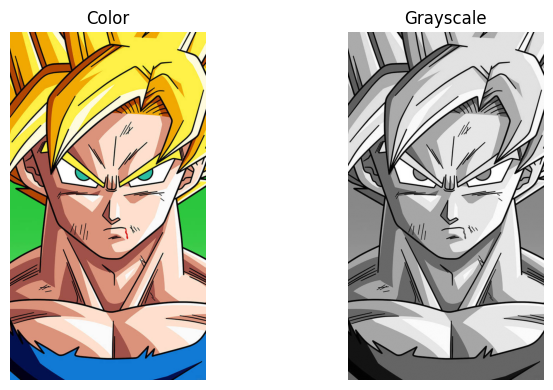

In [2]:
# Load image and convert to grayscale
color = cv2.imread('image1.jpg')
img = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)

show([color, img], ['Color', 'Grayscale'], cols=2)


## Step 2 — Laplacian Mask

The Laplacian is a 2nd-order derivative operator that highlights edges (rapid intensity changes).

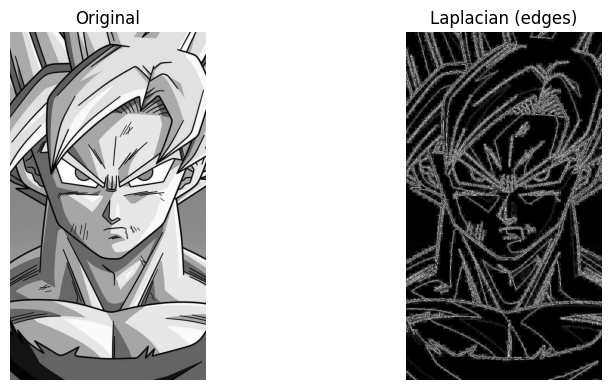

In [3]:
lap = cv2.Laplacian(img, cv2.CV_64F, ksize=3)
lap = np.uint8(np.absolute(lap))
show([img, lap], ['Original', 'Laplacian (edges)'])


## Step 3 — Enhanced Laplacian

`Enhanced = Original - Laplacian` — sharpens the image by adding edges back.

We use a Laplacian kernel with center = -4.

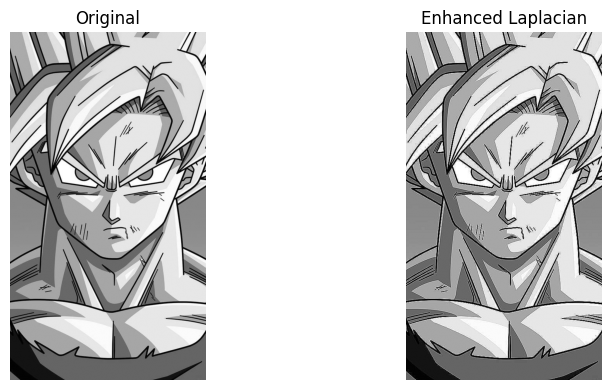

In [4]:
k = np.array([[0,1,0],[1,-4,1],[0,1,0]], np.float32)
lap_k = cv2.filter2D(img, cv2.CV_64F, k)

enhanced = img.astype(np.float32) - lap_k
enhanced = np.clip(enhanced, 0, 255).astype(np.uint8)
show([img, enhanced], ['Original', 'Enhanced Laplacian'])


## Step 4 — High-Boost Filter

`High-boost = A * Original - Laplacian`, where A >= 1.

- A = 1 → same as Enhanced Laplacian
- A > 1 → amplifies the original while keeping the sharpening

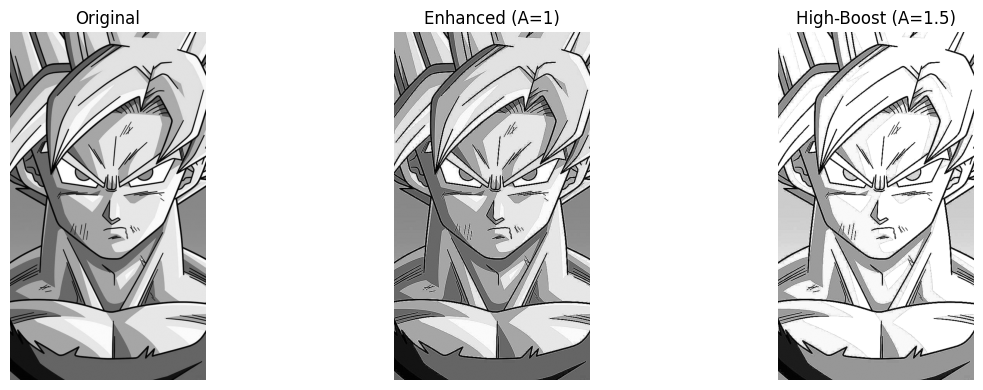

In [5]:
A = 1.5   # try 1.0, 1.5, 2.0
hb = A * img.astype(np.float32) - lap_k
hb = np.clip(hb, 0, 255).astype(np.uint8)
show([img, enhanced, hb],
     ['Original', 'Enhanced (A=1)', f'High-Boost (A={A})'])
